# Environmental variation and food-web associations

Reproducible analysis of the final environmental PCA and its associations with temporal food-web turnover and selected food-web properties. Exploratory PCA variants and superseded screening analyses are intentionally excluded.

In [1]:
# Shared configuration
from pathlib import Path
import os

# Directory containing the audited input CSV files.
# Set FOODWEB_DATA_DIR to use a different location without editing the notebook.
DATA_DIR = Path(os.environ.get("FOODWEB_DATA_DIR", ".")).resolve()
DATA_DIR.mkdir(parents=True, exist_ok=True)
print(f"Data/output directory: {DATA_DIR}")


Data/output directory: /content


## 1. Reduced environmental PCA

Summarize environmental variation using the final reduced 10-variable PCA. This section reproduces the PCA scores, loadings, explained variance, and associated diagnostics used in the manuscript.

In [2]:

from pathlib import Path
import warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from scipy.stats import spearmanr
warnings.filterwarnings("ignore")

BASE = DATA_DIR
FILE=BASE/"FW_lagoon_food_web_ metrics_by_sampling_AUDITED.csv"
if not FILE.exists():
    raise FileNotFoundError(f"Upload '{FILE.name}' to {BASE}")

raw=pd.read_csv(FILE)
raw.columns=[str(c).strip() for c in raw.columns]

def num(x):
    if pd.isna(x): return np.nan
    if isinstance(x,(int,float,np.integer,np.floating)): return float(x)
    s=str(x).strip().replace("\u00a0","").replace(" ","")
    if s=="" or s.lower() in {"na","nan","none","nd","n.d.","-"}: return np.nan
    if "," in s and "." in s:
        s=s.replace(".","").replace(",",".") if s.rfind(",")>s.rfind(".") else s.replace(",","")
    elif "," in s: s=s.replace(",",".")
    try: return float(s)
    except: return np.nan

wanted={
"Water temperature":"Water_temperature_(ºC)",
"pH":"pH",
"Conductivity":"Electric_conductivity_(µS.cm-1)",
"DO":"DO_(mg.L-1)",
"Depth":"Deep_(m)",
"Transparency":"Water_tranparency_(m)",
"Chl-a":"Chlorophyll-a_(µg.L-1)",
"SRP":"SRP_(µg.L-1)",
"AMT":"AMT_ (UFC.100mL-1)",
"TC":"TC_NMP.100mL-2",
}

missing=[v for v in wanted.values() if v not in raw.columns]
if missing: raise ValueError(f"Missing columns: {missing}")

dat=pd.DataFrame({"date":raw["date"].astype(str).str.strip()})
for k,v in wanted.items(): dat[k]=raw[v].map(num)

X=dat.set_index("date")
X["Chl-a"]=np.log10(X["Chl-a"]+1)
X["TC"]=np.log10(X["TC"])

print("Reduced environmental matrix:")
print(X.to_string())
print("\nMissing values:")
print(X.isna().sum().to_string())
print("\nTotal missing cells:",int(X.isna().sum().sum()))


Reduced environmental matrix:
            Water temperature    pH  Conductivity     DO  Depth  Transparency     Chl-a      SRP         AMT        TC
date                                                                                                                  
14/05/2016              14.27  7.01        323.00   2.21   0.50          0.21  1.435844   936.41  1137106.37  3.822524
09/07/2016              12.90  7.04        790.00   5.09   0.55          0.25  2.026737   839.85   770264.80  3.633468
10/09/2016              16.10  8.02        477.00  11.57   0.60          0.28  2.093106    39.22   740038.27  2.602060
20/01/2017              29.11  8.66        314.33   8.34   0.44          0.26  2.676785   610.01  1918446.78  3.885985
16/03/2017              21.43  7.01        144.50   1.44   0.52          0.24  2.026737   892.52  1921249.19  3.065169
06/04/2017              24.63  7.45        211.00   4.42   0.40          0.16  2.280214  1308.00  1734540.33  3.581111
29/06/2017        

In [3]:

def fit_pca(Xin, impute=True):
    if impute:
        imp=IterativeImputer(random_state=2026,max_iter=50,tol=1e-4,initial_strategy="median")
        U=pd.DataFrame(imp.fit_transform(Xin),index=Xin.index,columns=Xin.columns)
    else:
        U=Xin.dropna().copy()
    Z=StandardScaler().fit_transform(U)
    p=PCA().fit(Z)
    pcs=[f"PC{i+1}" for i in range(len(p.explained_variance_ratio_))]
    scores=pd.DataFrame(p.transform(Z),index=U.index,columns=pcs)
    loadings=pd.DataFrame(p.components_.T*np.sqrt(p.explained_variance_),
                          index=U.columns,columns=pcs)
    contrib=(loadings**2).div((loadings**2).sum(axis=0),axis=1)*100
    variance=pd.DataFrame({"PC":pcs,
        "explained_variance_ratio":p.explained_variance_ratio_,
        "cumulative_variance":np.cumsum(p.explained_variance_ratio_)})
    return U,p,scores,loadings,contrib,variance

U,p,scores,loadings,contrib,variance=fit_pca(X,True)
Ucc,pcc,scores_cc,loadings_cc,contrib_cc,variance_cc=fit_pca(X,False)

# save
U.to_csv(BASE/"stage4B21_reduced_matrix_imputed.csv")
scores.to_csv(BASE/"stage4B21_reduced_scores.csv")
loadings.to_csv(BASE/"stage4B21_reduced_loadings.csv")
contrib.to_csv(BASE/"stage4B21_reduced_contributions.csv")
variance.to_csv(BASE/"stage4B21_reduced_variance.csv",index=False)
scores_cc.to_csv(BASE/"stage4B21_complete_case_scores.csv")
loadings_cc.to_csv(BASE/"stage4B21_complete_case_loadings.csv")
variance_cc.to_csv(BASE/"stage4B21_complete_case_variance.csv",index=False)

print("REDUCED PCA — variance explained")
print(variance.to_string(index=False))
print(f"\nPC1 + PC2 = {100*variance.iloc[1].cumulative_variance:.2f}%")
print("\nLOADINGS PC1-PC2")
print(loadings[["PC1","PC2"]].to_string())
print("\nCONTRIBUTIONS PC1-PC2 (%)")
print(contrib[["PC1","PC2"]].to_string())


REDUCED PCA — variance explained
  PC  explained_variance_ratio  cumulative_variance
 PC1                  0.306483             0.306483
 PC2                  0.281268             0.587751
 PC3                  0.120914             0.708665
 PC4                  0.104999             0.813664
 PC5                  0.064843             0.878506
 PC6                  0.052248             0.930754
 PC7                  0.041015             0.971769
 PC8                  0.019849             0.991618
 PC9                  0.006817             0.998435
PC10                  0.001565             1.000000

PC1 + PC2 = 58.78%

LOADINGS PC1-PC2
                        PC1       PC2
Water temperature -0.042772 -0.614848
pH                 0.798499  0.153542
Conductivity      -0.413601  0.488809
DO                 0.441285  0.808769
Depth             -0.821460  0.365575
Transparency      -0.489347 -0.157306
Chl-a              0.915489  0.209039
SRP                0.113129 -0.779199
AMT            

In [4]:

# Sensitivity to the single DO imputation
rows=[]
for pc in ["PC1","PC2"]:
    idx=scores.index.intersection(scores_cc.index)
    rho=spearmanr(scores.loc[idx,pc],scores_cc.loc[idx,pc]).statistic
    rows.append({"PC":pc,"n_shared":len(idx),"rho_raw_sign":rho,"absolute_rho":abs(rho)})
sens=pd.DataFrame(rows)
sens.to_csv(BASE/"stage4B21_DO_imputation_sensitivity.csv",index=False)

# imputed value
imp=[]
for d in X.index:
    for c in X.columns:
        if pd.isna(X.loc[d,c]):
            imp.append({"date":d,"variable":c,"imputed_value":U.loc[d,c]})
imp=pd.DataFrame(imp)
imp.to_csv(BASE/"stage4B21_imputed_value.csv",index=False)

print("\nSENSITIVITY — reduced PCA vs complete cases")
print(sens.to_string(index=False))
print("\nIMPUTED CELL")
print(imp.to_string(index=False))



SENSITIVITY — reduced PCA vs complete cases
 PC  n_shared  rho_raw_sign  absolute_rho
PC1        15      0.992857      0.992857
PC2        15      1.000000      1.000000

IMPUTED CELL
      date variable  imputed_value
23/02/2018       DO       5.569549


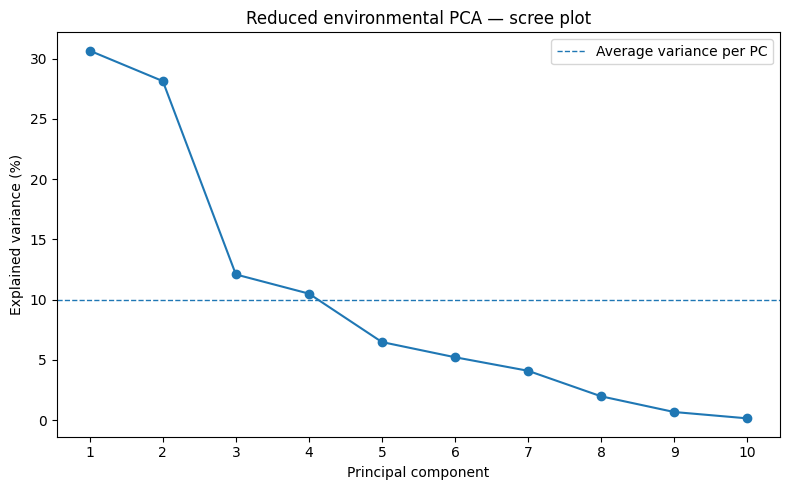

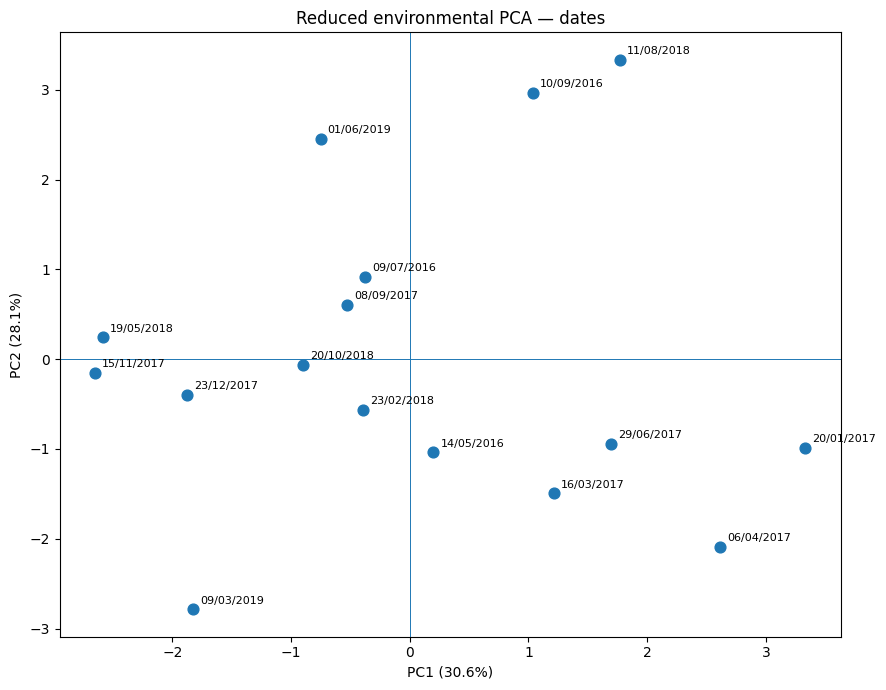

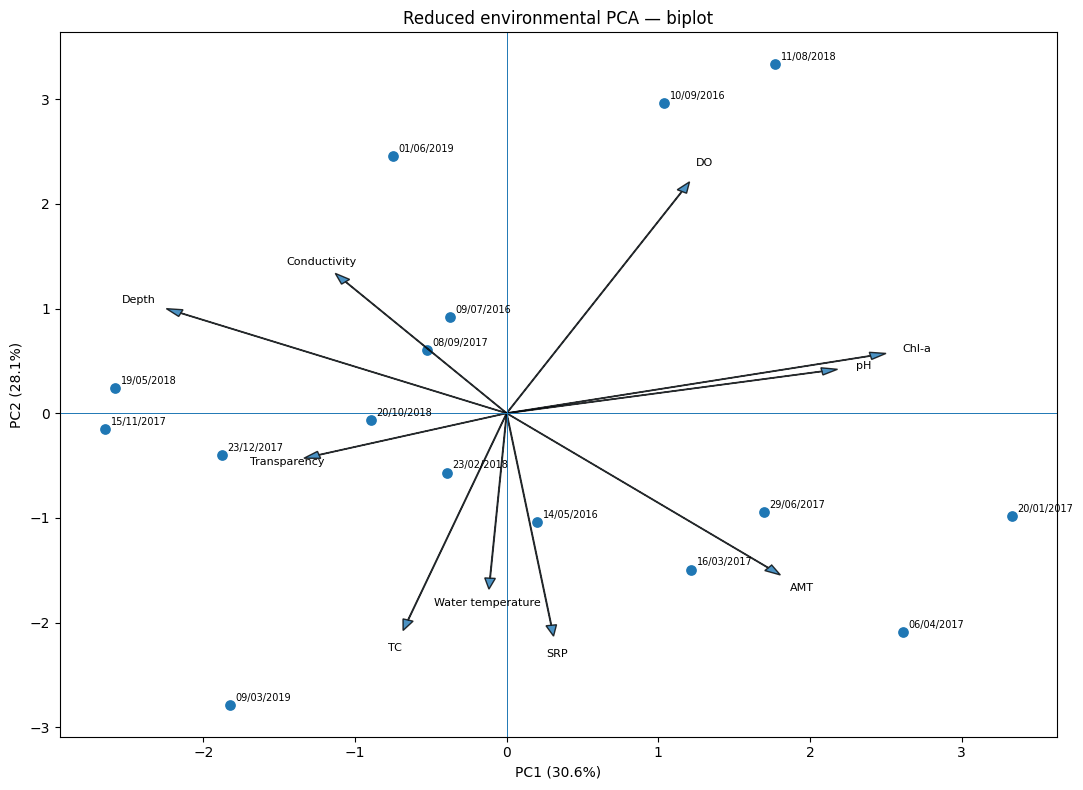

In [5]:

# Scree plot
ev=variance.explained_variance_ratio.values
fig,ax=plt.subplots(figsize=(8,5))
ax.plot(range(1,len(ev)+1),100*ev,marker="o")
ax.axhline(100/len(X.columns),ls="--",lw=1,label="Average variance per PC")
ax.set(xlabel="Principal component",ylabel="Explained variance (%)",
       title="Reduced environmental PCA — scree plot")
ax.set_xticks(range(1,len(ev)+1)); ax.legend()
fig.tight_layout()
fig.savefig(BASE/"stage4B21_fig1_scree.png",dpi=300,bbox_inches="tight")
fig.savefig(BASE/"stage4B21_fig1_scree.pdf",bbox_inches="tight")
plt.show()

# scores
fig,ax=plt.subplots(figsize=(9,7))
ax.scatter(scores.PC1,scores.PC2,s=60)
for d,r in scores.iterrows():
    ax.annotate(d,(r.PC1,r.PC2),xytext=(5,4),textcoords="offset points",fontsize=8)
ax.axhline(0,lw=.7); ax.axvline(0,lw=.7)
ax.set(xlabel=f"PC1 ({100*ev[0]:.1f}%)",ylabel=f"PC2 ({100*ev[1]:.1f}%)",
       title="Reduced environmental PCA — dates")
fig.tight_layout()
fig.savefig(BASE/"stage4B21_fig2_scores.png",dpi=300,bbox_inches="tight")
fig.savefig(BASE/"stage4B21_fig2_scores.pdf",bbox_inches="tight")
plt.show()

# biplot
fig,ax=plt.subplots(figsize=(11,8))
ax.scatter(scores.PC1,scores.PC2,s=45)
for d,r in scores.iterrows():
    ax.annotate(d,(r.PC1,r.PC2),xytext=(4,3),textcoords="offset points",fontsize=7)
sx=max(abs(scores.PC1).max(),1); sy=max(abs(scores.PC2).max(),1)
for var,r in loadings.iterrows():
    x,y=r.PC1*sx*.82,r.PC2*sy*.82
    ax.arrow(0,0,x,y,width=.004,head_width=.07,length_includes_head=True,alpha=.8)
    ax.text(x*1.08,y*1.08,var,fontsize=8,ha="center",va="center")
ax.axhline(0,lw=.7); ax.axvline(0,lw=.7)
ax.set(xlabel=f"PC1 ({100*ev[0]:.1f}%)",ylabel=f"PC2 ({100*ev[1]:.1f}%)",
       title="Reduced environmental PCA — biplot")
fig.tight_layout()
fig.savefig(BASE/"stage4B21_fig3_biplot.png",dpi=300,bbox_inches="tight")
fig.savefig(BASE/"stage4B21_fig3_biplot.pdf",bbox_inches="tight")
plt.show()


In [6]:

# Optional comparison with original 12-variable PCA scores
OLD=BASE/"stage4B2_main_imputed_scores.csv"
comparison_text="Original 12-variable score file not uploaded; optional comparison skipped."
if OLD.exists():
    old=pd.read_csv(OLD,index_col=0)
    rows=[]
    for pc in ["PC1","PC2"]:
        idx=scores.index.intersection(old.index)
        rho=spearmanr(scores.loc[idx,pc],old.loc[idx,pc]).statistic
        rows.append({"PC":pc,"n_shared":len(idx),"rho_raw_sign":rho,"absolute_rho":abs(rho)})
    oldcmp=pd.DataFrame(rows)
    oldcmp.to_csv(BASE/"stage4B21_vs_original_PC_correlations.csv",index=False)
    comparison_text=oldcmp.to_string(index=False)
print("\nOPTIONAL COMPARISON WITH ORIGINAL PCA")
print(comparison_text)

report=[]
report += ["STAGE 4B2.1 — REDUCED ENVIRONMENTAL PCA","="*72,
f"Dates: {len(scores)}; variables: {len(X.columns)}; complete-case dates: {len(scores_cc)}",
f"Missing cells imputed: {int(X.isna().sum().sum())}","",
"EXPLAINED VARIANCE",variance.to_string(index=False),"",
"LOADINGS PC1-PC2",loadings[["PC1","PC2"]].to_string(),"",
"CONTRIBUTIONS (%) PC1-PC2",contrib[["PC1","PC2"]].to_string(),"",
"DATE SCORES PC1-PC2",scores[["PC1","PC2"]].to_string(),"",
"DO IMPUTATION SENSITIVITY",sens.to_string(index=False),"",
"IMPUTED CELL",imp.to_string(index=False),"",
"OPTIONAL ORIGINAL-PCA COMPARISON",comparison_text]
txt="\n".join(report)
print("\n"+txt)
(BASE/"stage4B21_console_summary.txt").write_text(txt,encoding="utf-8")



OPTIONAL COMPARISON WITH ORIGINAL PCA
Original 12-variable score file not uploaded; optional comparison skipped.

STAGE 4B2.1 — REDUCED ENVIRONMENTAL PCA
Dates: 16; variables: 10; complete-case dates: 15
Missing cells imputed: 1

EXPLAINED VARIANCE
  PC  explained_variance_ratio  cumulative_variance
 PC1                  0.306483             0.306483
 PC2                  0.281268             0.587751
 PC3                  0.120914             0.708665
 PC4                  0.104999             0.813664
 PC5                  0.064843             0.878506
 PC6                  0.052248             0.930754
 PC7                  0.041015             0.971769
 PC8                  0.019849             0.991618
 PC9                  0.006817             0.998435
PC10                  0.001565             1.000000

LOADINGS PC1-PC2
                        PC1       PC2
Water temperature -0.042772 -0.614848
pH                 0.798499  0.153542
Conductivity      -0.413601  0.488809
DO      

2607

## 2. Environmental distance and temporal food-web turnover

Calculate environmental distances in retained PCA space and test their associations with taxonomic and trophic-functional turnover using date-label permutations.

In [9]:

from pathlib import Path
import warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from scipy.stats import spearmanr
from scipy.spatial.distance import pdist, squareform

warnings.filterwarnings("ignore")
BASE = DATA_DIR
ENV_FILE=BASE/"FW_lagoon_food_web_ metrics_by_sampling_AUDITED.csv"
TURN_FILE=BASE/"stage4A_pairwise_dissimilarity.csv"

missing=[p.name for p in [ENV_FILE,TURN_FILE] if not p.exists()]
if missing:
    raise FileNotFoundError("Upload to /content: "+", ".join(missing))

DATES=[
"14/05/2016","09/07/2016","10/09/2016","20/01/2017",
"16/03/2017","06/04/2017","29/06/2017","08/09/2017",
"15/11/2017","23/12/2017","23/02/2018","19/05/2018",
"11/08/2018","20/10/2018","09/03/2019","01/06/2019"]

def num(x):
    if pd.isna(x): return np.nan
    if isinstance(x,(int,float,np.integer,np.floating)): return float(x)
    s=str(x).strip().replace("\u00a0","").replace(" ","")
    if s=="" or s.lower() in {"na","nan","none","nd","n.d.","-"}: return np.nan
    if "," in s and "." in s:
        s=s.replace(".","").replace(",",".") if s.rfind(",")>s.rfind(".") else s.replace(",","")
    elif "," in s: s=s.replace(",",".")
    try: return float(s)
    except: return np.nan

raw=pd.read_csv(ENV_FILE)
raw.columns=[str(c).strip() for c in raw.columns]
cols={
"Water temperature":"Water_temperature_(ºC)",
"pH":"pH",
"Conductivity":"Electric_conductivity_(µS.cm-1)",
"DO":"DO_(mg.L-1)",
"Depth":"Deep_(m)",
"Transparency":"Water_tranparency_(m)",
"Chl-a":"Chlorophyll-a_(µg.L-1)",
"SRP":"SRP_(µg.L-1)",
"AMT":"AMT_ (UFC.100mL-1)",
"TC":"TC_NMP.100mL-2",
}
req=["date"]+list(cols.values())
miss=[c for c in req if c not in raw.columns]
if miss: raise ValueError("Environmental columns missing: "+str(miss))

E=pd.DataFrame({"date":raw["date"].astype(str).str.strip()})
for k,v in cols.items(): E[k]=raw[v].map(num)
E=E.set_index("date").loc[DATES]
E["Chl-a"]=np.log10(E["Chl-a"]+1)
E["TC"]=np.log10(E["TC"])

imp=IterativeImputer(random_state=2026,max_iter=50,tol=1e-4,initial_strategy="median")
Ei=pd.DataFrame(imp.fit_transform(E),index=E.index,columns=E.columns)
Z=StandardScaler().fit_transform(Ei)
pca=PCA().fit(Z)
scores=pd.DataFrame(pca.transform(Z),index=E.index,
                    columns=[f"PC{i+1}" for i in range(len(E.columns))])

print("Frozen reduced PCA reconstructed.")
print("PC1-PC4 cumulative variance:",
      round(100*pca.explained_variance_ratio_[:4].sum(),3),"%")
print("Missing environmental cells imputed:",int(E.isna().sum().sum()))


Frozen reduced PCA reconstructed.
PC1-PC4 cumulative variance: 81.366 %
Missing environmental cells imputed: 1


In [10]:

# Read Stage 4A pairwise turnover and identify its date columns robustly
T=pd.read_csv(TURN_FILE)
print("Stage 4A columns:",list(T.columns))

candidate_pairs=[("date1","date2"),("date_1","date_2"),("date_i","date_j")]
datecols=None
for a,b in candidate_pairs:
    if a in T.columns and b in T.columns:
        datecols=(a,b); break
if datecols is None:
    # fallback: first two columns containing 'date'
    dc=[c for c in T.columns if "date" in c.lower()]
    if len(dc)>=2: datecols=(dc[0],dc[1])
if datecols is None:
    raise ValueError("Could not identify the two date columns in Stage 4A pairwise table.")

d1c,d2c=datecols
for c in [d1c,d2c]:
    T[c]=T[c].astype(str).str.strip()

responses=[
"taxonomic_node_dissimilarity",
"taxonomic_link_dissimilarity",
"functional_category_dissimilarity",
"functional_link_dissimilarity",
]
miss=[c for c in responses if c not in T.columns]
if miss: raise ValueError("Missing Stage 4A turnover columns: "+str(miss))

if len(T)!=120:
    print(f"WARNING: expected 120 date pairs, found {len(T)}.")

# Environmental PC1-PC4 Euclidean distance matrix
Denv=pd.DataFrame(squareform(pdist(scores[["PC1","PC2","PC3","PC4"]])),
                  index=scores.index,columns=scores.index)

T["environmental_distance_PC1_PC4"]=[
    Denv.loc[a,b] for a,b in zip(T[d1c],T[d2c])
]

T.to_csv(BASE/"stage4C1_integrated_pairwise_table.csv",index=False)
print("\nIntegrated pairs:",len(T))
print(T[[d1c,d2c,"environmental_distance_PC1_PC4"]+responses].head().to_string(index=False))


Stage 4A columns: ['date1', 'date2', 'taxonomic_node_dissimilarity', 'taxonomic_link_dissimilarity', 'functional_category_dissimilarity', 'functional_link_dissimilarity', 'node_dissimilarity_compression', 'link_dissimilarity_compression']

Integrated pairs: 120
     date1      date2  environmental_distance_PC1_PC4  taxonomic_node_dissimilarity  taxonomic_link_dissimilarity  functional_category_dissimilarity  functional_link_dissimilarity
14/05/2016 09/07/2016                        2.476529                      0.567568                      0.875000                                0.0                       0.066667
14/05/2016 10/09/2016                        4.721672                      0.514286                      0.788462                                0.0                       0.176471
14/05/2016 20/01/2017                        4.762384                      0.487179                      0.906475                                0.0                       0.176471
14/05/2016 16/03/2

In [11]:

# Build turnover matrices in the fixed 16-date order
def matrix_from_pairs(df,value_col):
    M=pd.DataFrame(np.zeros((len(DATES),len(DATES))),index=DATES,columns=DATES,dtype=float)
    M[:]=np.nan
    np.fill_diagonal(M.values,0.0)
    for _,r in df.iterrows():
        a,b=r[d1c],r[d2c]
        M.loc[a,b]=M.loc[b,a]=float(r[value_col])
    if M.isna().any().any():
        raise ValueError(f"Incomplete pairwise matrix for {value_col}")
    return M

turn_mats={r:matrix_from_pairs(T,r) for r in responses}

# upper triangle
iu=np.triu_indices(len(DATES),1)
env_vec=Denv.values[iu]

# Mantel-style permutation: permute date labels of environmental matrix
N_PERM=9999
rng=np.random.default_rng(20261003)
perm_rhos={r:np.empty(N_PERM) for r in responses}
obs={}

for r,M in turn_mats.items():
    obs[r]=spearmanr(env_vec,M.values[iu]).statistic

for k in range(N_PERM):
    perm=rng.permutation(len(DATES))
    ep=Denv.values[np.ix_(perm,perm)][iu]
    for r,M in turn_mats.items():
        perm_rhos[r][k]=spearmanr(ep,M.values[iu]).statistic

rows=[]
for r in responses:
    rr=obs[r]
    null=perm_rhos[r]
    p=(1+np.sum(np.abs(null)>=abs(rr)))/(N_PERM+1)
    rows.append({
        "response":r,
        "spearman_rho_descriptive":rr,
        "permutation_p_two_sided":p,
        "null_rho_mean":np.mean(null),
        "null_rho_sd":np.std(null,ddof=1)
    })
res=pd.DataFrame(rows)
res.to_csv(BASE/"stage4C1_environment_turnover_mantel_results.csv",index=False)
print(res.to_string(index=False))


                         response  spearman_rho_descriptive  permutation_p_two_sided  null_rho_mean  null_rho_sd
     taxonomic_node_dissimilarity                  0.127444                   0.3152       0.000555     0.124363
     taxonomic_link_dissimilarity                  0.031615                   0.8076       0.000566     0.128750
functional_category_dissimilarity                 -0.045147                   0.8005      -0.002745     0.171588
    functional_link_dissimilarity                 -0.084144                   0.6390      -0.002609     0.170332


In [12]:

# Pre-specified contrasts:
# Does environment-track turnover more strongly taxonomically than functionally?
# Node composition: taxonomic nodes vs functional categories
# Links: taxonomic links vs functional links
contrasts=[
("nodes_minus_categories","taxonomic_node_dissimilarity","functional_category_dissimilarity"),
("taxonomic_links_minus_functional_links","taxonomic_link_dissimilarity","functional_link_dissimilarity")
]
crow=[]
for label,tax,fun in contrasts:
    delta_obs=obs[tax]-obs[fun]
    delta_null=perm_rhos[tax]-perm_rhos[fun]
    p=(1+np.sum(np.abs(delta_null)>=abs(delta_obs)))/(N_PERM+1)
    crow.append({
        "contrast":label,
        "rho_taxonomic":obs[tax],
        "rho_functional":obs[fun],
        "delta_rho_tax_minus_function":delta_obs,
        "permutation_p_two_sided":p
    })
cres=pd.DataFrame(crow)
cres.to_csv(BASE/"stage4C1_taxonomic_vs_functional_contrasts.csv",index=False)
print("\nTAXONOMIC vs FUNCTIONAL ENVIRONMENT–TURNOVER CONTRASTS")
print(cres.to_string(index=False))

# Also descriptive association between environmental distance and compression itself.
for comp in ["node_dissimilarity_compression","link_dissimilarity_compression"]:
    if comp in T.columns:
        rho=spearmanr(T["environmental_distance_PC1_PC4"],T[comp]).statistic
        print(f"\nDescriptive rho environmental distance vs {comp}: {rho:.4f}")



TAXONOMIC vs FUNCTIONAL ENVIRONMENT–TURNOVER CONTRASTS
                              contrast  rho_taxonomic  rho_functional  delta_rho_tax_minus_function  permutation_p_two_sided
                nodes_minus_categories       0.127444       -0.045147                      0.172591                   0.2747
taxonomic_links_minus_functional_links       0.031615       -0.084144                      0.115759                   0.5556

Descriptive rho environmental distance vs node_dissimilarity_compression: 0.1783

Descriptive rho environmental distance vs link_dissimilarity_compression: 0.0826


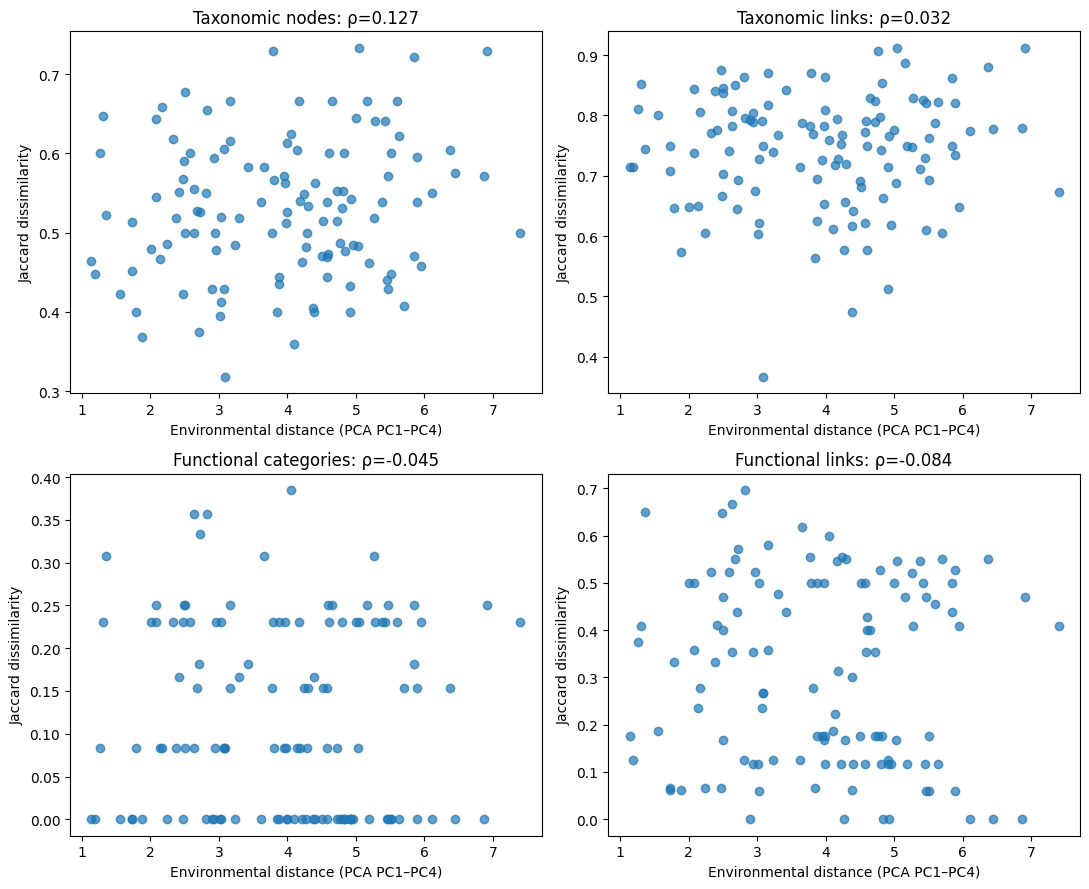

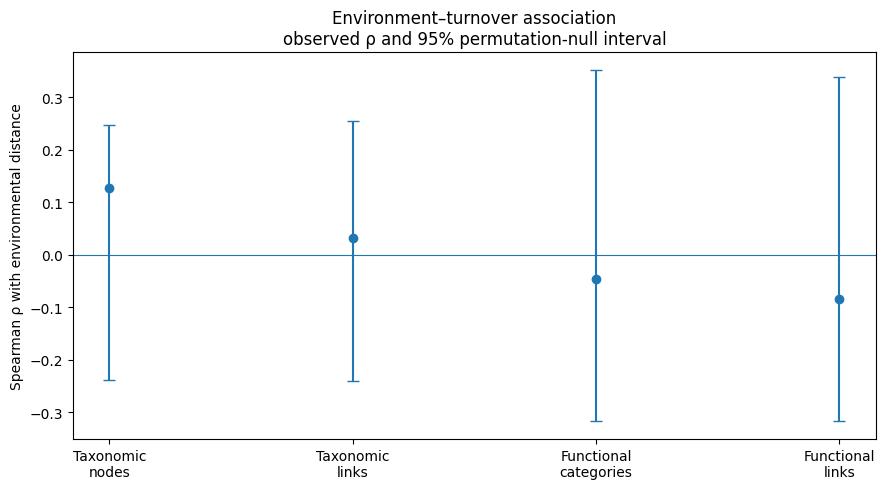

In [13]:

# Figure: four environment-turnover relationships
labels={
"taxonomic_node_dissimilarity":"Taxonomic nodes",
"taxonomic_link_dissimilarity":"Taxonomic links",
"functional_category_dissimilarity":"Functional categories",
"functional_link_dissimilarity":"Functional links",
}
fig,axs=plt.subplots(2,2,figsize=(11,9))
for ax,r in zip(axs.ravel(),responses):
    ax.scatter(T["environmental_distance_PC1_PC4"],T[r],alpha=.7)
    ax.set(xlabel="Environmental distance (PCA PC1–PC4)",
           ylabel="Jaccard dissimilarity",
           title=f"{labels[r]}: ρ={obs[r]:.3f}")
fig.tight_layout()
fig.savefig(BASE/"stage4C1_environment_turnover_scatter.png",dpi=300,bbox_inches="tight")
fig.savefig(BASE/"stage4C1_environment_turnover_scatter.pdf",bbox_inches="tight")
plt.show()

# Figure: observed rho with permutation null intervals
fig,ax=plt.subplots(figsize=(9,5))
x=np.arange(len(responses))
obsvals=[obs[r] for r in responses]
lo=[np.quantile(perm_rhos[r],.025) for r in responses]
hi=[np.quantile(perm_rhos[r],.975) for r in responses]
ax.errorbar(x,obsvals,
            yerr=[np.array(obsvals)-np.array(lo),np.array(hi)-np.array(obsvals)],
            fmt="o",capsize=4)
ax.axhline(0,lw=.8)
ax.set_xticks(x,["Taxonomic\nnodes","Taxonomic\nlinks",
                 "Functional\ncategories","Functional\nlinks"])
ax.set_ylabel("Spearman ρ with environmental distance")
ax.set_title("Environment–turnover association\nobserved ρ and 95% permutation-null interval")
fig.tight_layout()
fig.savefig(BASE/"stage4C1_environment_turnover_permutation.png",dpi=300,bbox_inches="tight")
fig.savefig(BASE/"stage4C1_environment_turnover_permutation.pdf",bbox_inches="tight")
plt.show()


In [14]:

report=[
"STAGE 4C1 — ENVIRONMENTAL DISTANCE × TAXONOMIC/FUNCTIONAL TURNOVER",
"="*82,
f"Dates: {len(DATES)}; pairwise comparisons: {len(T)}; permutations: {N_PERM}",
f"Environmental representation: reduced 10-variable PCA, Euclidean distance in PC1-PC4",
f"PC1-PC4 cumulative environmental variance: {100*pca.explained_variance_ratio_[:4].sum():.3f}%",
f"Environmental missing cells imputed: {int(E.isna().sum().sum())}",
"",
"ENVIRONMENT–TURNOVER RESULTS",
res.to_string(index=False),
"",
"TAXONOMIC VS FUNCTIONAL CONTRASTS",
cres.to_string(index=False),
"",
"INTERPRETATION GUARDRAILS",
"- The 120 pairwise comparisons are not independent; inferential p-values use date-label permutations.",
"- Spearman rho values describe monotonic association between environmental and compositional distances.",
"- A stronger taxonomic than functional association would be consistent with functional compression, but does not demonstrate resilience.",
"- A non-significant functional association does not mean functional organization is random.",
"- Environmental distance uses PC1-PC4; PC1-PC2 remain the preferred axes for ecological visualization/interpretation.",
"- No network metric or environmental variable was selected based on these results."
]
txt="\n".join(report)
(BASE/"stage4C1_console_summary.txt").write_text(txt,encoding="utf-8")
print("\n"+txt)



STAGE 4C1 — ENVIRONMENTAL DISTANCE × TAXONOMIC/FUNCTIONAL TURNOVER
Dates: 16; pairwise comparisons: 120; permutations: 9999
Environmental representation: reduced 10-variable PCA, Euclidean distance in PC1-PC4
PC1-PC4 cumulative environmental variance: 81.366%
Environmental missing cells imputed: 1

ENVIRONMENT–TURNOVER RESULTS
                         response  spearman_rho_descriptive  permutation_p_two_sided  null_rho_mean  null_rho_sd
     taxonomic_node_dissimilarity                  0.127444                   0.3152       0.000555     0.124363
     taxonomic_link_dissimilarity                  0.031615                   0.8076       0.000566     0.128750
functional_category_dissimilarity                 -0.045147                   0.8005      -0.002745     0.171588
    functional_link_dissimilarity                 -0.084144                   0.6390      -0.002609     0.170332

TAXONOMIC VS FUNCTIONAL CONTRASTS
                              contrast  rho_taxonomic  rho_functional 

## 3. Environmental state and selected food-web properties

Evaluate pre-specified taxonomic and functional food-web properties against PC1 and PC2 and retain residual temporal diagnostics.

In [16]:

from pathlib import Path
import warnings, re, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from scipy.stats import spearmanr
import statsmodels.api as sm

warnings.filterwarnings("ignore")
BASE = DATA_DIR

ENV_FILE=BASE/"FW_lagoon_food_web_ metrics_by_sampling_AUDITED.csv"
STRUCT_FILE=BASE/"temporal_structural_observed_metrics_stage3_v31.csv"
FUNC_FILE=BASE/"temporal_functional_observed_metrics_stage2.csv"

needed=[ENV_FILE,STRUCT_FILE,FUNC_FILE]
missing=[p.name for p in needed if not p.exists()]
if missing:
    print("Files currently in folder:")
    print("\n".join(sorted(p.name for p in BASE.glob("*"))))
    raise FileNotFoundError(
        "\nUpload these files (or edit STRUCT_FILE/FUNC_FILE if filenames differ):\n- "
        +"\n- ".join(missing)
    )

DATES=[
"14/05/2016","09/07/2016","10/09/2016","20/01/2017",
"16/03/2017","06/04/2017","29/06/2017","08/09/2017",
"15/11/2017","23/12/2017","23/02/2018","19/05/2018",
"11/08/2018","20/10/2018","09/03/2019","01/06/2019"]

def num(x):
    if pd.isna(x): return np.nan
    if isinstance(x,(int,float,np.integer,np.floating)): return float(x)
    s=str(x).strip().replace("\u00a0","").replace(" ","")
    if s=="" or s.lower() in {"na","nan","none","nd","n.d.","-"}: return np.nan
    if "," in s and "." in s:
        s=s.replace(".","").replace(",",".") if s.rfind(",")>s.rfind(".") else s.replace(",","")
    elif "," in s: s=s.replace(",",".")
    try: return float(s)
    except: return np.nan

def norm(s):
    return re.sub(r'[^a-z0-9]+','_',str(s).lower()).strip('_')

print("INPUTS")
for p in needed: print(" -",p.name)


INPUTS
 - FW_lagoon_food_web_ metrics_by_sampling_AUDITED.csv
 - temporal_structural_observed_metrics_stage3_v31.csv
 - temporal_functional_observed_metrics_stage2.csv


In [17]:

# Reconstruct frozen reduced 10-variable PCA
raw=pd.read_csv(ENV_FILE)
raw.columns=[str(c).strip() for c in raw.columns]
cols={
"Water temperature":"Water_temperature_(ºC)",
"pH":"pH",
"Conductivity":"Electric_conductivity_(µS.cm-1)",
"DO":"DO_(mg.L-1)",
"Depth":"Deep_(m)",
"Transparency":"Water_tranparency_(m)",
"Chl-a":"Chlorophyll-a_(µg.L-1)",
"SRP":"SRP_(µg.L-1)",
"AMT":"AMT_ (UFC.100mL-1)",
"TC":"TC_NMP.100mL-2",
}
miss=[v for v in cols.values() if v not in raw.columns]
if miss: raise ValueError("Missing environmental columns: "+str(miss))

E=pd.DataFrame({"date":raw["date"].astype(str).str.strip()})
for k,v in cols.items(): E[k]=raw[v].map(num)
E=E.set_index("date").loc[DATES]
E["Chl-a"]=np.log10(E["Chl-a"]+1)
E["TC"]=np.log10(E["TC"])

imp=IterativeImputer(random_state=2026,max_iter=50,tol=1e-4,initial_strategy="median")
Ei=pd.DataFrame(imp.fit_transform(E),index=E.index,columns=E.columns)
Z=StandardScaler().fit_transform(Ei)
pca=PCA().fit(Z)
scores=pd.DataFrame(pca.transform(Z),index=E.index,
                    columns=[f"PC{i+1}" for i in range(len(E.columns))])

print(f"PC1={100*pca.explained_variance_ratio_[0]:.2f}%")
print(f"PC2={100*pca.explained_variance_ratio_[1]:.2f}%")
print(f"PC1+PC2={100*pca.explained_variance_ratio_[:2].sum():.2f}%")


PC1=30.65%
PC2=28.13%
PC1+PC2=58.78%


In [18]:

# Load observed metric tables and audit columns
Sraw=pd.read_csv(STRUCT_FILE)
Fraw=pd.read_csv(FUNC_FILE)
print("STRUCTURAL COLUMNS:")
print(list(Sraw.columns))
print("\nFUNCTIONAL COLUMNS:")
print(list(Fraw.columns))

def find_date_col(df):
    exact=[c for c in df.columns if norm(c) in {"date","sampling_date","sample_date"}]
    if exact: return exact[0]
    cand=[c for c in df.columns if "date" in norm(c)]
    if cand: return cand[0]
    raise ValueError("Could not identify date column.")

sd=find_date_col(Sraw); fd=find_date_col(Fraw)
Sraw[sd]=Sraw[sd].astype(str).str.strip()
Fraw[fd]=Fraw[fd].astype(str).str.strip()

# Explicit aliases only; fail loudly if a pre-specified metric cannot be identified.
aliases={
"S":["S","n_nodes","nodes","richness","taxonomic_richness","functional_richness"],
"L":[
    "L",
    "L_between_categories",
    "n_edges",
    "edges",
    "links",
    "n_links"
],
"connectance":["connectance","C"],
"max_trophic_level":["max_trophic_level","max_TL","maximum_trophic_level","maxTL"],
"out_in_assortativity":[
    "out_in_degree_assortativity",
    "out_in_assortativity",
    "assortativity_out_in",
    "degree_assortativity_out_in",
    "out-in_assortativity"
],

"transitivity":[
    "undirected_projection_transitivity",
    "transitivity",
    "directed_transitivity"
],
}

def pick(df,key):
    lookup={norm(c):c for c in df.columns}
    for a in aliases[key]:
        if norm(a) in lookup: return lookup[norm(a)]
    return None

selected={
"struct_S":pick(Sraw,"S"),
"struct_connectance":pick(Sraw,"connectance"),
"struct_maxTL":pick(Sraw,"max_trophic_level"),
"struct_assort":pick(Sraw,"out_in_assortativity"),
"struct_transitivity":pick(Sraw,"transitivity"),
"func_S":pick(Fraw,"S"),
"func_L":pick(Fraw,"L"),
}
print("\nMATCHED COLUMNS:")
for k,v in selected.items(): print(f"{k}: {v}")

bad=[k for k,v in selected.items() if v is None]
if bad:
    raise ValueError(
        "Could not identify these pre-specified metrics: "+str(bad)+
        "\nPlease inspect the printed columns and add the exact column name to aliases."
    )

S=Sraw.set_index(sd).loc[DATES]
F=Fraw.set_index(fd).loc[DATES]

D=pd.DataFrame(index=DATES)
D["PC1"]=scores.loc[DATES,"PC1"]
D["PC2"]=scores.loc[DATES,"PC2"]
D["tax_S"]=S[selected["struct_S"]].map(num)
D["tax_connectance"]=S[selected["struct_connectance"]].map(num)
D["tax_maxTL"]=S[selected["struct_maxTL"]].map(num)
D["tax_assortativity"]=S[selected["struct_assort"]].map(num)
D["tax_transitivity"]=S[selected["struct_transitivity"]].map(num)
D["func_S"]=F[selected["func_S"]].map(num)
D["func_L"]=F[selected["func_L"]].map(num)

if D.isna().any().any():
    print("\nMissing integrated values:")
    print(D.isna().sum())
    raise ValueError("Missing values found after integration; inspect inputs before modeling.")

D.to_csv(BASE/"stage4C2_integrated_date_level_table.csv",index_label="date")
print("\nINTEGRATED TABLE")
print(D.to_string())


STRUCTURAL COLUMNS:
['date', 'S', 'L', 'connectance', 'linkage_density_L_per_S', 'mean_total_degree', 'mean_in_degree', 'mean_out_degree', 'n_basal', 'prop_basal', 'n_intermediate', 'prop_intermediate', 'n_top', 'prop_top', 'n_isolates', 'weak_components', 'strong_components', 'is_DAG', 'mean_trophic_level', 'median_trophic_level', 'max_trophic_level', 'mean_omnivory_index', 'prop_omnivores_OI_gt_0', 'mean_betweenness', 'mean_closeness', 'mean_directed_clustering', 'undirected_projection_transitivity', 'out_in_degree_assortativity', 'infomap_n_modules', 'infomap_codelength', 'directed_modularity_Q_of_infomap_partition', 'max_chain_edges', 'mean_chain_edges', 'n_basal_terminal_paths']

FUNCTIONAL COLUMNS:
['date', 'n_taxa_observed', 'L_taxonomic_realized', 'S', 'L_between_categories', 'n_within_category_interactions_excluded', 'L_projected_total_before_loop_exclusion', 'connectance_L_over_S_Sminus1', 'linkage_density_L_per_S', 'mean_total_degree', 'mean_in_degree', 'mean_out_degree', 'n

In [19]:

# Descriptive Spearman associations (not used for metric selection)
responses=["tax_S","tax_connectance","tax_maxTL","tax_assortativity",
           "tax_transitivity","func_S","func_L"]
spears=[]
for y in responses:
    for pc in ["PC1","PC2"]:
        rr=spearmanr(D[pc],D[y])
        spears.append({"response":y,"predictor":pc,"rho":rr.statistic,"p_naive":rr.pvalue})
spears=pd.DataFrame(spears)
spears.to_csv(BASE/"stage4C2_descriptive_spearman.csv",index=False)
print(spears.to_string(index=False))


         response predictor       rho  p_naive
            tax_S       PC1  0.500737 0.048197
            tax_S       PC2 -0.268042 0.315514
  tax_connectance       PC1 -0.132353 0.625106
  tax_connectance       PC2  0.341176 0.195933
        tax_maxTL       PC1  0.009758 0.971389
        tax_maxTL       PC2 -0.279728 0.294048
tax_assortativity       PC1  0.061765 0.820242
tax_assortativity       PC2  0.100000 0.712516
 tax_transitivity       PC1  0.035825 0.895208
 tax_transitivity       PC2 -0.026869 0.921318
           func_S       PC1  0.235008 0.380952
           func_S       PC2 -0.388667 0.136807
           func_L       PC1  0.329638 0.212469
           func_L       PC2 -0.059663 0.826270


In [20]:

# Parsimonious OLS models.
# Main: y ~ PC1 + PC2
# Richness-adjusted sensitivity for taxonomic topology only: y ~ PC1 + PC2 + tax_S
# (No richness adjustment for tax_S itself or functional S/L.)

def fit_model(y,preds,label):
    X=sm.add_constant(D[preds].astype(float))
    mod=sm.OLS(D[y].astype(float),X).fit()
    ci=mod.conf_int(alpha=.05)
    rows=[]
    for term in mod.params.index:
        rows.append({
            "response":y,"model":label,"term":term,
            "estimate":mod.params[term],
            "CI95_low":ci.loc[term,0],"CI95_high":ci.loc[term,1],
            "p_value":mod.pvalues[term],
            "R2":mod.rsquared,"adj_R2":mod.rsquared_adj,
            "AIC":mod.aic,"n":int(mod.nobs)
        })
    # temporal residual diagnostics in chronological order
    resid=pd.Series(mod.resid,index=D.index)
    lag1=np.corrcoef(resid.iloc[:-1],resid.iloc[1:])[0,1]
    dw=sm.stats.stattools.durbin_watson(resid.values)
    diag={"response":y,"model":label,"lag1_residual_correlation":lag1,
          "durbin_watson":dw,"n":int(mod.nobs)}
    return rows,diag,mod

allrows=[]; diags=[]; models={}
for y in responses:
    rr,dd,m=fit_model(y,["PC1","PC2"],"main_PC1_PC2")
    allrows+=rr; diags.append(dd); models[(y,"main")]=m

for y in ["tax_connectance","tax_maxTL","tax_assortativity","tax_transitivity"]:
    rr,dd,m=fit_model(y,["PC1","PC2","tax_S"],"richness_adjusted")
    allrows+=rr; diags.append(dd); models[(y,"richness")]=m

coef=pd.DataFrame(allrows)
diag=pd.DataFrame(diags)
coef.to_csv(BASE/"stage4C2_model_coefficients.csv",index=False)
diag.to_csv(BASE/"stage4C2_residual_temporal_diagnostics.csv",index=False)

print("MODEL COEFFICIENTS — PC terms")
print(coef[coef.term.isin(["PC1","PC2","tax_S"])].to_string(index=False))
print("\nTEMPORAL RESIDUAL DIAGNOSTICS")
print(diag.to_string(index=False))


MODEL COEFFICIENTS — PC terms
         response             model  term  estimate  CI95_low  CI95_high  p_value       R2    adj_R2        AIC  n
            tax_S      main_PC1_PC2   PC1  2.527219  0.666472   4.387966 0.011620 0.416461  0.326686 105.587491 16
            tax_S      main_PC1_PC2   PC2 -0.735162 -2.677528   1.207203 0.428276 0.416461  0.326686 105.587491 16
  tax_connectance      main_PC1_PC2   PC1 -0.002375 -0.011120   0.006370 0.567441 0.131000 -0.002692 -65.941650 16
  tax_connectance      main_PC1_PC2   PC2  0.005370 -0.003758   0.014499 0.225995 0.131000 -0.002692 -65.941650 16
        tax_maxTL      main_PC1_PC2   PC1 -0.000891 -0.069069   0.067288 0.977915 0.172141  0.044778  -0.223802 16
        tax_maxTL      main_PC1_PC2   PC2 -0.054155 -0.125324   0.017015 0.124153 0.172141  0.044778  -0.223802 16
tax_assortativity      main_PC1_PC2   PC1  0.017745 -0.083925   0.119414 0.712216 0.085341 -0.055376  12.563351 16
tax_assortativity      main_PC1_PC2   PC2  0.05083

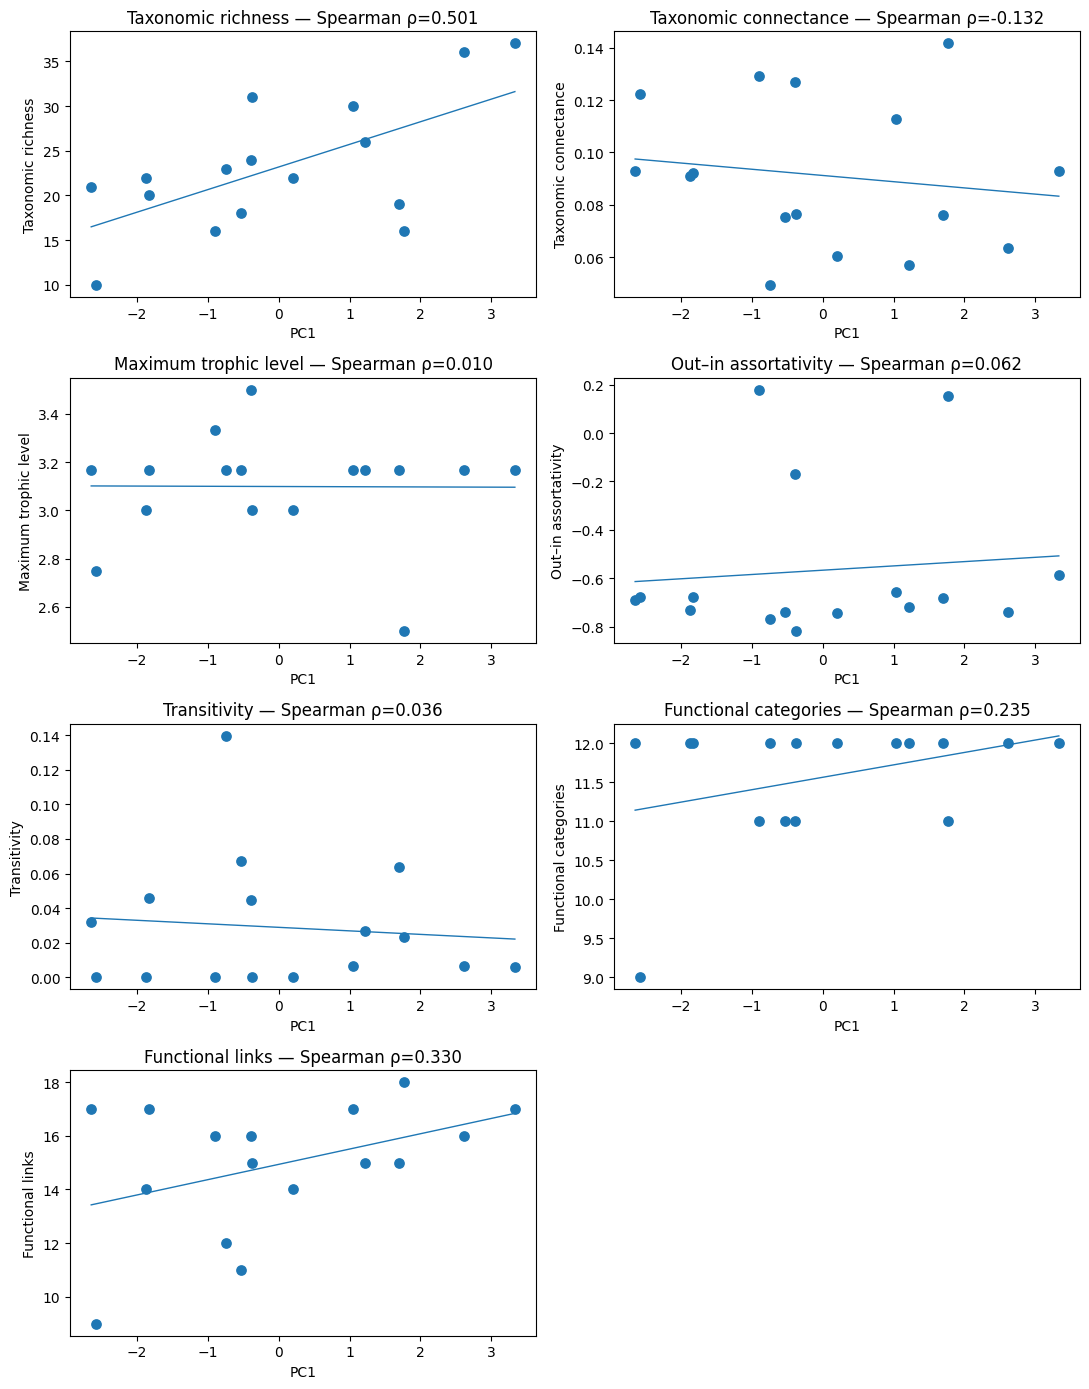

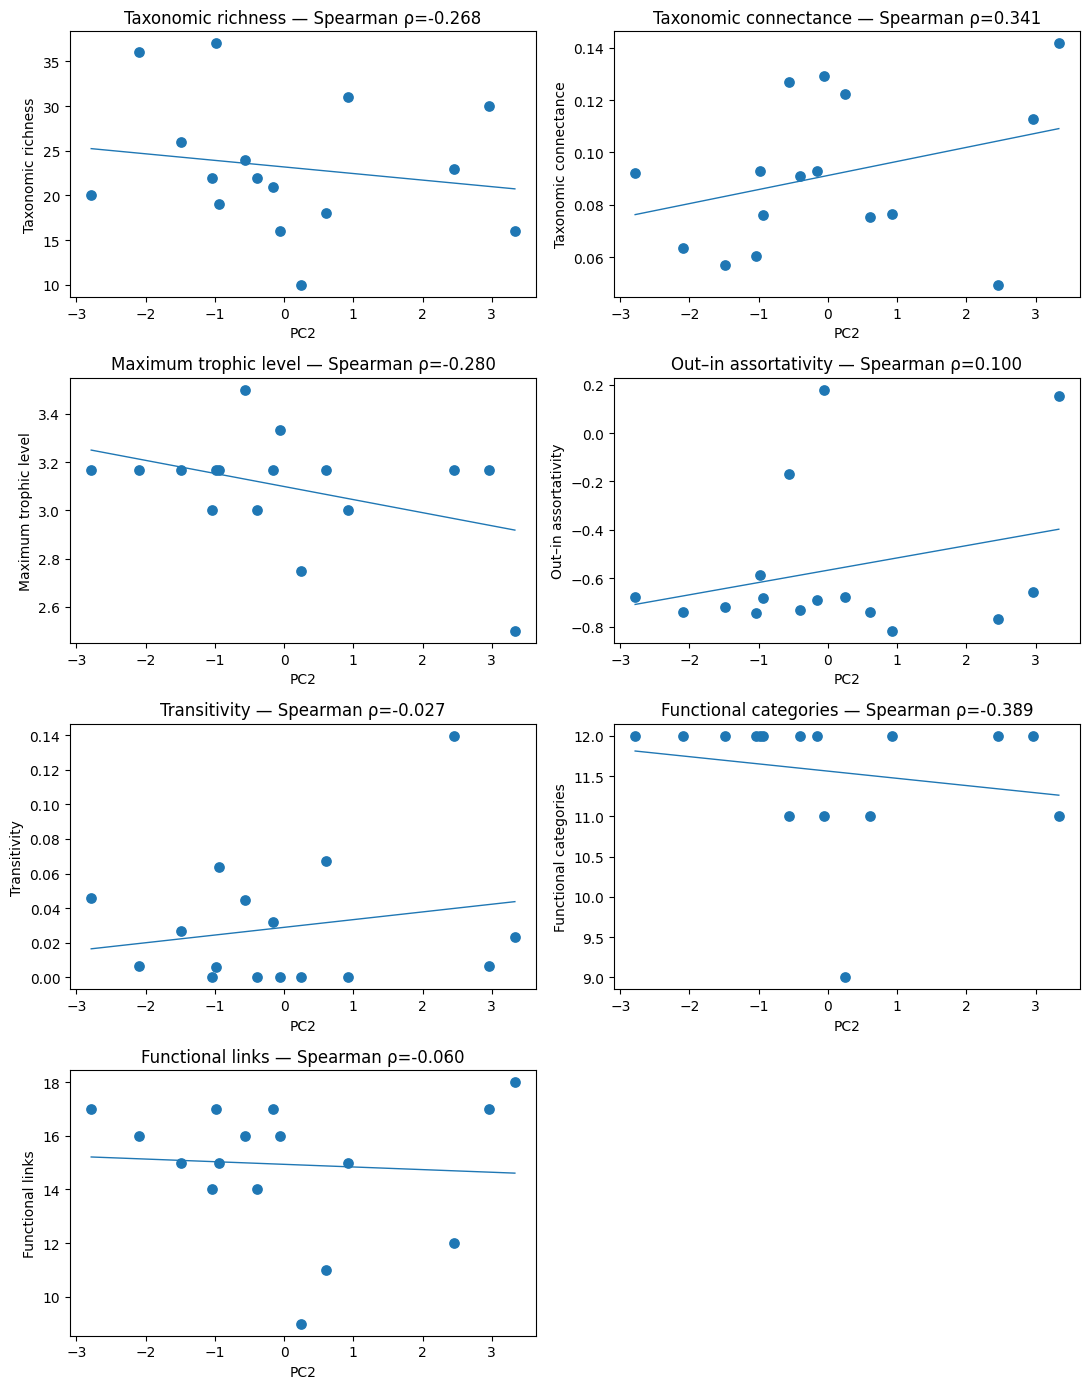

In [21]:

# Compact visualization of pre-specified responses vs PC1 and PC2
pretty={
"tax_S":"Taxonomic richness",
"tax_connectance":"Taxonomic connectance",
"tax_maxTL":"Maximum trophic level",
"tax_assortativity":"Out–in assortativity",
"tax_transitivity":"Transitivity",
"func_S":"Functional categories",
"func_L":"Functional links",
}
for pc in ["PC1","PC2"]:
    fig,axs=plt.subplots(4,2,figsize=(11,14))
    axs=axs.ravel()
    for ax,y in zip(axs,responses):
        ax.scatter(D[pc],D[y],s=45)
        # simple fitted line for visualization only
        z=np.polyfit(D[pc],D[y],1)
        xx=np.linspace(D[pc].min(),D[pc].max(),100)
        ax.plot(xx,np.polyval(z,xx),lw=1)
        rho=spears.query("response==@y and predictor==@pc").rho.iloc[0]
        ax.set(xlabel=pc,ylabel=pretty[y],title=f"{pretty[y]} — Spearman ρ={rho:.3f}")
    axs[-1].axis("off")
    fig.tight_layout()
    fig.savefig(BASE/f"stage4C2_{pc}_responses.png",dpi=300,bbox_inches="tight")
    fig.savefig(BASE/f"stage4C2_{pc}_responses.pdf",bbox_inches="tight")
    plt.show()


In [22]:

# Compact final report
main_pc=coef[(coef.model=="main_PC1_PC2") & (coef.term.isin(["PC1","PC2"]))].copy()
adj_pc=coef[(coef.model=="richness_adjusted") & (coef.term.isin(["PC1","PC2","tax_S"]))].copy()

report=[
"STAGE 4C2 — ENVIRONMENTAL STATE × SELECTED FOOD-WEB PROPERTIES",
"="*82,
f"Dates: {len(D)}",
f"Environmental PCA: PC1={100*pca.explained_variance_ratio_[0]:.3f}%, "
f"PC2={100*pca.explained_variance_ratio_[1]:.3f}%, "
f"cumulative={100*pca.explained_variance_ratio_[:2].sum():.3f}%",
"",
"PRE-SPECIFIED RESPONSES",
", ".join(responses),
"",
"DESCRIPTIVE SPEARMAN",
spears.to_string(index=False),
"",
"MAIN MODELS: response ~ PC1 + PC2",
main_pc.to_string(index=False),
"",
"RICHNESS-ADJUSTED SENSITIVITY (taxonomic topology)",
adj_pc.to_string(index=False),
"",
"RESIDUAL TEMPORAL DIAGNOSTICS",
diag.to_string(index=False),
"",
"INTERPRETATION GUARDRAILS",
"- Metrics were selected before inspecting PC associations.",
"- With n=16, emphasize effect sizes, confidence intervals and consistency; do not treat p<0.05 as the sole criterion.",
"- Richness-adjusted models are sensitivity analyses for topology metrics, not automatic replacements for main models.",
"- Lag-1 residual correlation and Durbin-Watson are diagnostics; AR(1) is not imposed automatically.",
"- Binary networks represent realized presence/absence pathways, not interaction strength, abundance or energy flux.",
"- Associations with PC1/PC2 are contemporaneous and do not establish environmental causation."
]
txt="\n".join(report)
(BASE/"stage4C2_console_summary.txt").write_text(txt,encoding="utf-8")
print("\n"+txt)



STAGE 4C2 — ENVIRONMENTAL STATE × SELECTED FOOD-WEB PROPERTIES
Dates: 16
Environmental PCA: PC1=30.648%, PC2=28.127%, cumulative=58.775%

PRE-SPECIFIED RESPONSES
tax_S, tax_connectance, tax_maxTL, tax_assortativity, tax_transitivity, func_S, func_L

DESCRIPTIVE SPEARMAN
         response predictor       rho  p_naive
            tax_S       PC1  0.500737 0.048197
            tax_S       PC2 -0.268042 0.315514
  tax_connectance       PC1 -0.132353 0.625106
  tax_connectance       PC2  0.341176 0.195933
        tax_maxTL       PC1  0.009758 0.971389
        tax_maxTL       PC2 -0.279728 0.294048
tax_assortativity       PC1  0.061765 0.820242
tax_assortativity       PC2  0.100000 0.712516
 tax_transitivity       PC1  0.035825 0.895208
 tax_transitivity       PC2 -0.026869 0.921318
           func_S       PC1  0.235008 0.380952
           func_S       PC2 -0.388667 0.136807
           func_L       PC1  0.329638 0.212469
           func_L       PC2 -0.059663 0.826270

MAIN MODELS: response 

## 4. AR(1) sensitivity analysis for taxonomic richness

Evaluate the PC1–taxonomic richness association with a first-order autoregressive sensitivity model.

In [23]:
import platform
print(platform.python_version())

3.13.16


In [27]:
from pathlib import Path
import warnings, numpy as np, pandas as pd, statsmodels.api as sm
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
warnings.filterwarnings("ignore")
BASE = DATA_DIR
ENV_FILE=BASE/"FW_lagoon_food_web_ metrics_by_sampling_AUDITED.csv"
STRUCT_FILE=BASE/"temporal_structural_observed_metrics_stage3_v31.csv"
for p in [ENV_FILE,STRUCT_FILE]:
    if not p.exists(): raise FileNotFoundError(f"Upload: {p.name}")
DATES=["14/05/2016","09/07/2016","10/09/2016","20/01/2017","16/03/2017","06/04/2017","29/06/2017","08/09/2017","15/11/2017","23/12/2017","23/02/2018","19/05/2018","11/08/2018","20/10/2018","09/03/2019","01/06/2019"]
def num(x):
    if pd.isna(x): return np.nan
    if isinstance(x,(int,float,np.integer,np.floating)): return float(x)
    s=str(x).strip().replace("\u00a0","").replace(" ","")
    if "," in s and "." in s: s=s.replace(".","").replace(",",".") if s.rfind(",")>s.rfind(".") else s.replace(",","")
    elif "," in s: s=s.replace(",",".")
    try:return float(s)
    except:return np.nan
print("Inputs:",ENV_FILE.name,";",STRUCT_FILE.name)

Inputs: FW_lagoon_food_web_ metrics_by_sampling_AUDITED.csv ; temporal_structural_observed_metrics_stage3_v31.csv


In [28]:
raw=pd.read_csv(ENV_FILE); raw.columns=[str(c).strip() for c in raw.columns]
cols={"Water temperature":"Water_temperature_(ºC)","pH":"pH","Conductivity":"Electric_conductivity_(µS.cm-1)","DO":"DO_(mg.L-1)","Depth":"Deep_(m)","Transparency":"Water_tranparency_(m)","Chl-a":"Chlorophyll-a_(µg.L-1)","SRP":"SRP_(µg.L-1)","AMT":"AMT_ (UFC.100mL-1)","TC":"TC_NMP.100mL-2"}
E=pd.DataFrame({"date":raw["date"].astype(str).str.strip()})
for k,v in cols.items(): E[k]=raw[v].map(num)
E=E.set_index("date").loc[DATES]
E["Chl-a"]=np.log10(E["Chl-a"]+1); E["TC"]=np.log10(E["TC"])
imp=IterativeImputer(random_state=2026,max_iter=50,tol=1e-4,initial_strategy="median")
Ei=pd.DataFrame(imp.fit_transform(E),index=E.index,columns=E.columns)
Z=StandardScaler().fit_transform(Ei); pca=PCA().fit(Z)
scores=pd.DataFrame(pca.transform(Z),index=E.index,columns=[f"PC{i+1}" for i in range(10)])
print("PC1, PC2, cumulative:",pca.explained_variance_ratio_[0],pca.explained_variance_ratio_[1],pca.explained_variance_ratio_[:2].sum())

PC1, PC2, cumulative: 0.3064834206214997 0.28126758052356127 0.587751001145061


In [29]:
Sraw=pd.read_csv(STRUCT_FILE); Sraw["date"]=Sraw["date"].astype(str).str.strip(); Sraw=Sraw.set_index("date")
D=pd.DataFrame({"PC1":scores.loc[DATES,"PC1"],"PC2":scores.loc[DATES,"PC2"],"S":Sraw.loc[DATES,"S"].map(num)})
D.index=pd.to_datetime(D.index,dayfirst=True); D=D.sort_index()
if D.isna().any().any(): raise ValueError(D.isna().sum())
X=sm.add_constant(D[["PC1","PC2"]]); y=D["S"]
ols=sm.OLS(y,X).fit()
glsar_model=sm.GLSAR(y,X,rho=1); glsar=glsar_model.iterative_fit(maxiter=100)
rho=float(np.atleast_1d(glsar_model.rho)[0])
def extract(m,name):
    ci=m.conf_int()
    return pd.DataFrame({"method":name,"term":["PC1","PC2"],"estimate":[m.params["PC1"],m.params["PC2"]],"SE":[m.bse["PC1"],m.bse["PC2"]],"CI95_low":[ci.loc["PC1",0],ci.loc["PC2",0]],"CI95_high":[ci.loc["PC1",1],ci.loc["PC2",1]],"p_value":[m.pvalues["PC1"],m.pvalues["PC2"]]})
comparison=pd.concat([extract(ols,"OLS"),extract(glsar,"GLSAR_AR1")],ignore_index=True)
comparison.to_csv(BASE/"stage4C21_richness_AR1_coefficients.csv",index=False)
olsres=np.asarray(ols.resid); gres=np.asarray(glsar.resid)
summary=f"""STAGE 4C2.1 — FINAL TEMPORAL SENSITIVITY
Dates: {len(D)}
Model: S ~ PC1 + PC2
Estimated AR(1) rho: {rho:.6f}

{comparison.to_string(index=False)}

OLS residual lag1: {np.corrcoef(olsres[:-1],olsres[1:])[0,1]:.6f}
OLS Durbin-Watson: {sm.stats.stattools.durbin_watson(olsres):.6f}
GLSAR raw residual lag1: {np.corrcoef(gres[:-1],gres[1:])[0,1]:.6f}
GLSAR raw residual Durbin-Watson: {sm.stats.stattools.durbin_watson(gres):.6f}

Interpretation:
- Compare PC1 direction, magnitude and 95% CI between OLS and GLSAR(1).
- If uncertainty expands across zero, describe the association as sensitive/suggestive.
- Do not use this check to reopen model selection or test additional responses.
"""
print(summary)
(BASE/"stage4C21_richness_AR1_summary.txt").write_text(summary,encoding="utf-8")

STAGE 4C2.1 — FINAL TEMPORAL SENSITIVITY
Dates: 16
Model: S ~ PC1 + PC2
Estimated AR(1) rho: 0.331200

   method term  estimate       SE  CI95_low  CI95_high  p_value
      OLS  PC1  2.527219 0.861310  0.666472   4.387966 0.011620
      OLS  PC2 -0.735162 0.899090 -2.677528   1.207203 0.428276
GLSAR_AR1  PC1  2.373450 0.922590  0.363300   4.383601 0.024429
GLSAR_AR1  PC2 -0.779443 0.855226 -2.642820   1.083933 0.380035

OLS residual lag1: 0.311085
OLS Durbin-Watson: 1.354352
GLSAR raw residual lag1: 0.318310
GLSAR raw residual Durbin-Watson: 1.334330

Interpretation:
- Compare PC1 direction, magnitude and 95% CI between OLS and GLSAR(1).
- If uncertainty expands across zero, describe the association as sensitive/suggestive.
- Do not use this check to reopen model selection or test additional responses.



814